In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'unzip', 'NMT')
pth_out = os.path.join(pth_data, 'cancer', 'human', 'NMT', 'processed')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'human', 'NMT', 'processed')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'SKNSHm_NORtoMES_merge.h5ad'))
adata

AnnData object with n_obs × n_vars = 22396 × 28071
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'myOrig.ident', 'myOrig.ident2', 'Timepoint', 'ident'
    uns: 'X_name'
    obsm: 'PCA', 'UMAP'
    layers: 'logcounts'

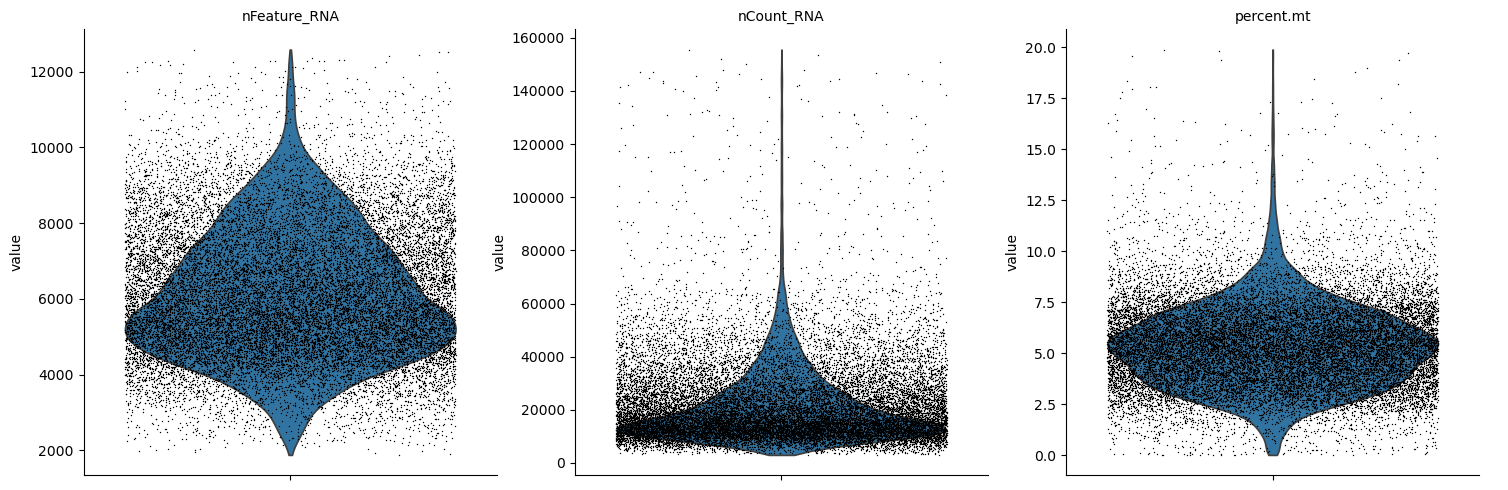

In [4]:
sc.pl.violin(adata, ['nFeature_RNA', 'nCount_RNA', 'percent.mt'], jitter = .4, multi_panel = True)

In [5]:
adata = adata[
    (adata.obs.nFeature_RNA < 10000) &
    (adata.obs.nCount_RNA < 60000) &
    (adata.obs['percent.mt'] < 10)].copy()
adata

AnnData object with n_obs × n_vars = 21371 × 28071
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'myOrig.ident', 'myOrig.ident2', 'Timepoint', 'ident'
    uns: 'X_name'
    obsm: 'PCA', 'UMAP'
    layers: 'logcounts'

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3678 over-dispersed features (0:00:05) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.



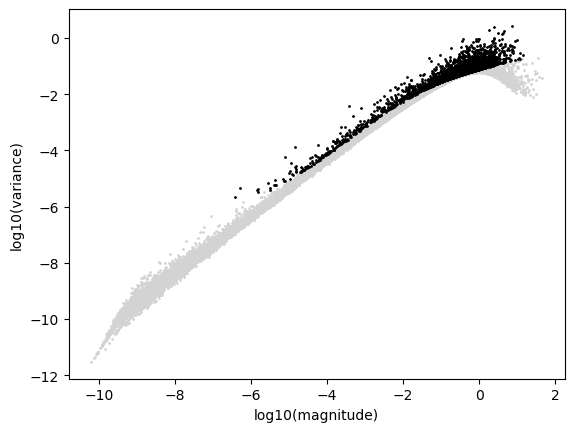

In [6]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata, plot = True)

In [7]:
sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, 'Timepoint')

2026-05-17 21:24:38,417 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
OpenBLAS warning: precompiled NUM_THREADS exceeded, adding auxiliary array for thread metadata.
To avoid this warning, please rebuild your copy of OpenBLAS with a larger NUM_THREADS setting
or set the environment variable OPENBLAS_NUM_THREADS to 64 or lower
2026-05-17 21:24:44,659 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-05-17 21:24:44,871 - harmonypy - INFO - Iteration 1 of 10
2026-05-17 21:24:50,331 - harmonypy - INFO - Iteration 2 of 10
2026-05-17 21:24:56,359 - harmonypy - INFO - Iteration 3 of 10
2026-05-17 21:25:02,221 - harmonypy - INFO - Converged after 3 iterations


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


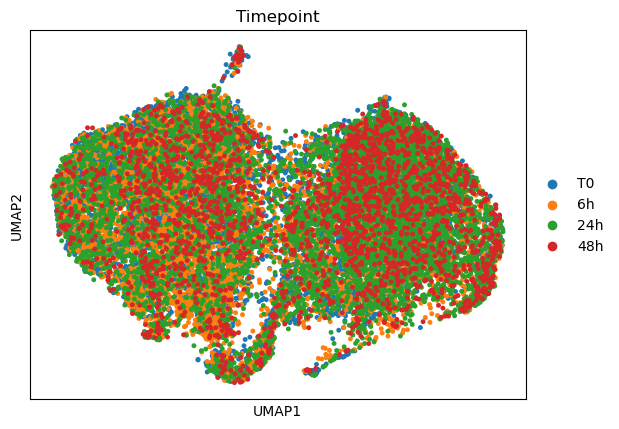

In [8]:
sc.pp.neighbors(adata, n_neighbors = 30, use_rep = 'X_pca_harmony')
sc.tl.umap(adata, spread = 3)
sc.pl.umap(adata, color = 'Timepoint', size = 50)

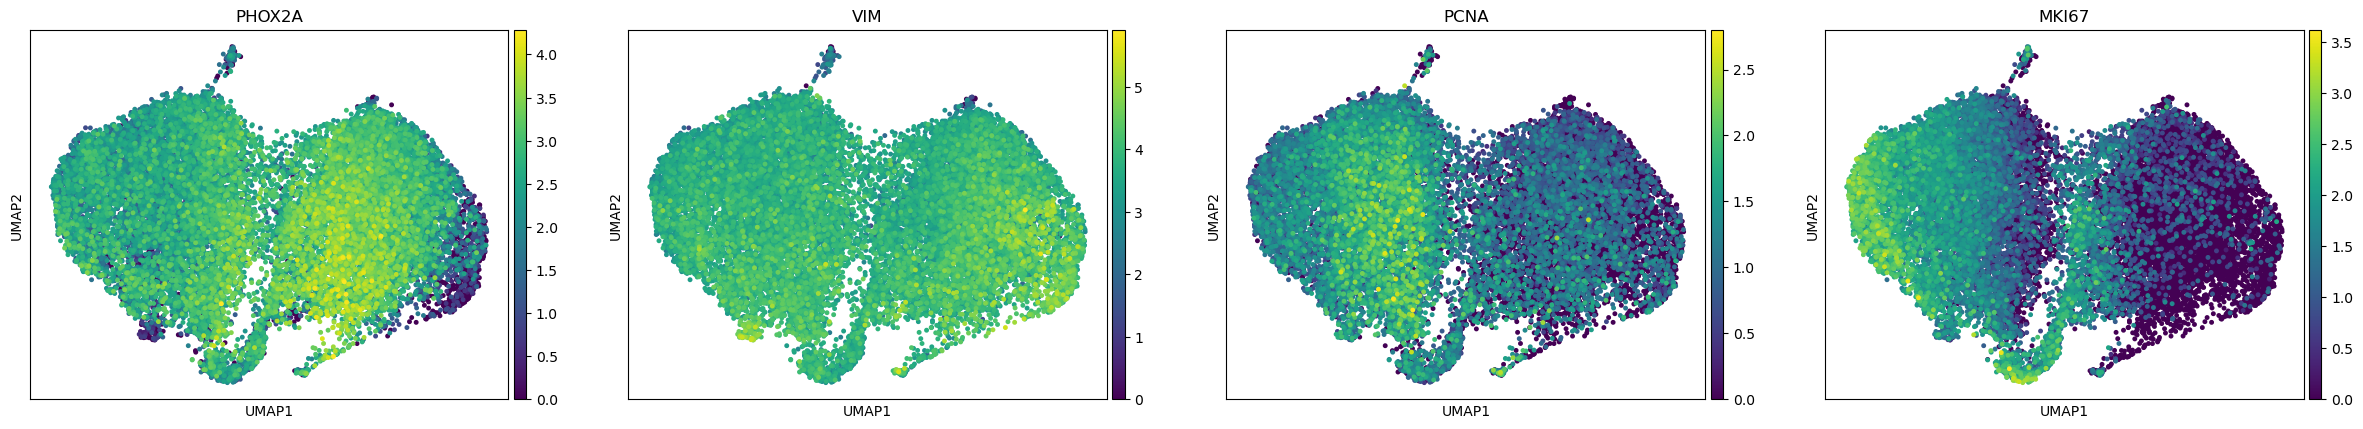

In [9]:
sc.pl.umap(adata, color = ['PHOX2A', 'VIM', 'PCNA', 'MKI67'], size = 50)

/tmp/ipykernel_1360780/3302607421.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution = 1.1)


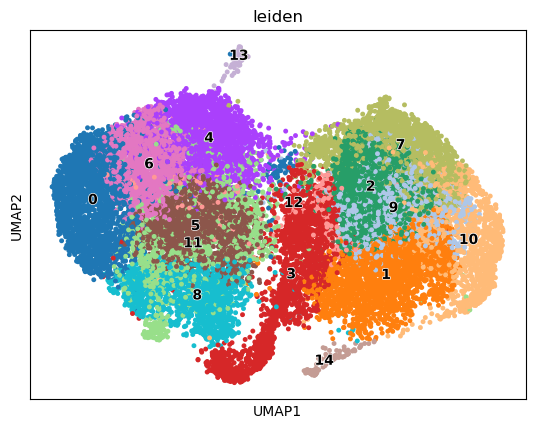

In [10]:
sc.tl.leiden(adata, resolution = 1.1)
sc.pl.umap(adata, color = 'leiden', size = 50, legend_loc = 'on data', legend_fontoutline = True)

In [11]:
adata = adata[adata.obs.leiden != '13'].copy()
adata

AnnData object with n_obs × n_vars = 21272 × 27739
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'myOrig.ident', 'myOrig.ident2', 'Timepoint', 'ident', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'X_name', 'log1p', 'pca', 'neighbors', 'umap', 'Timepoint_colors', 'leiden', 'leiden_colors'
    obsm: 'PCA', 'UMAP', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'logcounts'
    obsp: 'distances', 'connectivities'

In [12]:
celltype_dict = {
    '0'  : 'Proliferating Noradrenergic',
    '1'  : 'Noradrenergic',
    '2'  : 'Noradrenergic',
    '3'  : 'Cycling Noradrenergic',
    '4'  : 'Proliferating Noradrenergic',
    '5'  : 'Proliferating Noradrenergic',
    '6'  : 'Proliferating Noradrenergic',
    '7'  : 'Noradrenergic',
    '8'  : 'Proliferating Noradrenergic',
    '9'  : 'Noradrenergic',
    '10' : 'Mesenchymal',
    '11' : 'Proliferating Noradrenergic',
    '12' : 'Cycling Noradrenergic',
    '14' : 'Cycling Mesenchymal'}

adata.obs['celltype'] = adata.obs.leiden.map(celltype_dict).astype('category')

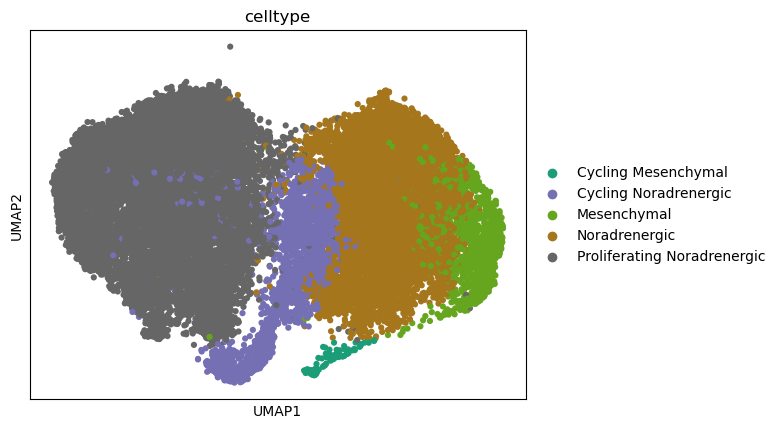

In [13]:
sc.pl.umap(adata, color = 'celltype', size = 80, palette = 'Dark2')

In [14]:
adata.write(os.path.join(pth_out, 'SK-N-SH.h5ad'))

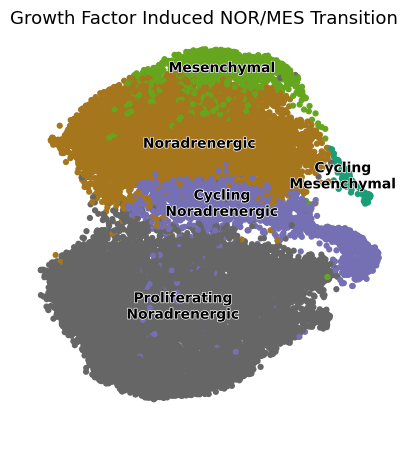

In [68]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'celltype', size = 80,
           dimensions = [1, 0], legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_xaxis(); xlim = ax.get_xlim()
ax.set_xlim(left = xlim[0] - 2)

label_dict = {
    'Cycling Mesenchymal'         : 'Cycling\nMesenchymal',
    'Cycling Noradrenergic'       : 'Cycling\nNoradrenergic',
    'Proliferating Noradrenergic' : 'Proliferating\nNoradrenergic'}

pos_dict = {
    'Cycling Mesenchymal'         : (.8, 1.2),
    'Cycling Noradrenergic'       : (1, 1),
    'Mesenchymal'                 : (-.5, .8),
    'Noradrenergic'               : (-2, -.25),
    'Proliferating Noradrenergic' : (-1, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

ax.set_title('Growth Factor Induced NOR/MES Transition', size = 13)
ax.text(.5, -.05, ' ', ha = 'center', transform = ax.transAxes)
fn = os.path.join(pth_fig, 'SK-N-SH.pdf')
plt.savefig(fn, bbox_inches = 'tight')